# Tutorial 1 — ASTER, Mount Rainier

> Reading this on the docs site? To run it, [open a Codespace](https://stereopipeline-quickstart.readthedocs.io/en/latest/start/codespaces.html): ASP and `asp-plot` are already installed there.

From two satellite images to a 3D model of the terrain (a DEM) in about 10 minutes. The images come from ASTER, an instrument on NASA's Terra satellite that photographs the ground twice in one pass: once looking straight down, once looking back. The difference between the two views gives the height of the ground, the way two eyes give depth. [How stereo works](https://stereopipeline-quickstart.readthedocs.io/en/latest/concepts/stereo-photogrammetry.html) explains it.

> **In a new Codespace this notebook starts running by itself after a ~30 second wait.** Scroll down to follow it: each step shows its progress while it runs, then its results. To run it again, click **Run All** at the top:
> ![The top of the window: the notebook's toolbar, with the Run All button boxed](../start/figures/run-all.png)

The steps:

1. Download the scene and unpack the two images.
2. Look at the viewing geometry.
3. Look at the raw input images.
4. Orthorectify the images onto a coarse map of the terrain.
5. Look at the orthorectified images.
6. Run stereo matching and build the DEM.
7. Make a PDF report.
8. Download the results.

Scene: ASTER over Mount Rainier, Washington, 31 July 2017, a window of about 38 × 36 km around the summit.

In [1]:
from pathlib import Path

from utils import run, run_stereo, timer

DATA = "../data/aster_rainier"
LOGS = f"{DATA}/logs"

!mkdir -p {DATA}

# The Copernicus reference DEM, fetched by the download step.
REF_DEM = f"{DATA}/ref/cop30_rainier.tif"

# The processing window, xmin ymin xmax ymax in UTM zone 10N (EPSG:32610)
# meters: about 38 x 36 km around the summit.
T_SRS = "EPSG:32610"
T_PROJWIN = "577305 5172975 615705 5209035"

# ICESat-2 points and figure selections shipped with this tutorial, fetched by
# the download step. The report replays them with --reuse-selections, so no
# SlideRule request is made. Set FRESH_ICESAT2 = True to request fresh
# ICESat-2 data from SlideRule instead.
FRESH_ICESAT2 = False
SHIPPED_SELECTIONS = f"{DATA}/icesat2_shipped/figure_selections.yml"

## 1. Download the scene

One ASTER scene (about 55 MB). ASP's `aster2asp` unpacks it into the two images and a camera file for each, which records where the satellite was and how it was pointed.

> About a minute.

In [2]:
run(f"bash ../scripts/download_aster.sh {DATA}", log=f"{LOGS}/download.log", label="Downloading the scene")

if Path(f"{DATA}/out-Band3N.tif").exists():
    print(f"{DATA}/out-Band3N.tif exists — skipping aster2asp. Delete out-Band3*.* to reprocess.")
else:
    run(f"aster2asp {DATA}/dataDir -o {DATA}/out", log=f"{LOGS}/aster2asp.log", label="Extracting images and cameras")

!ls -1 {DATA}/out-Band3*.tif {DATA}/out-Band3*.xml

bash ../scripts/download_aster.sh ../data/aster_rainier


✅ **Downloading the scene**: done in 11 s. Full log: `../data/aster_rainier/logs/download.log`

aster2asp ../data/aster_rainier/dataDir -o ../data/aster_rainier/out


✅ **Extracting images and cameras**: done in 7 s. Full log: `../data/aster_rainier/logs/aster2asp.log`

../data/aster_rainier/out-Band3B.tif
../data/aster_rainier/out-Band3B.xml
../data/aster_rainier/out-Band3N.tif
../data/aster_rainier/out-Band3N.xml


## 2. Viewing geometry

The two views, read from the camera files. [More on viewing geometry](https://stereopipeline-quickstart.readthedocs.io/en/latest/concepts/stereo-photogrammetry.html#viewing-geometry).

> About half a minute.

✅ **Plotting the stereo geometry**: done in 16 s

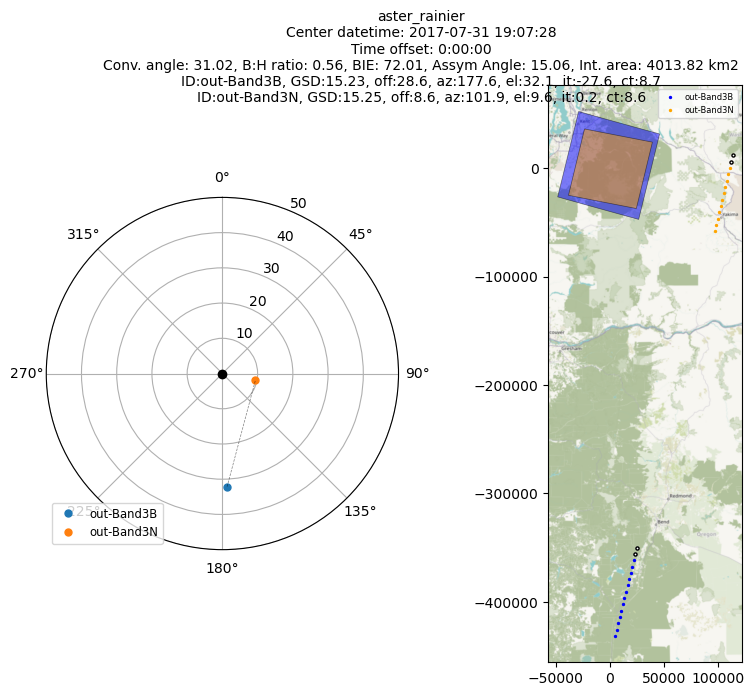

In [3]:
with timer("Plotting the stereo geometry"):
    import contextily
    from asp_plot.stereo_geometry import StereoGeometryPlotter

    # The map tiles were fetched when the Codespace was built
    # (scripts/prefetch_basemap.py); without them, this fetches them itself.
    contextily.set_cache_dir("../data/basemap_cache")

    geometry = StereoGeometryPlotter(
        inputs=[f"{DATA}/out-Band3N.xml", f"{DATA}/out-Band3B.xml"]
    )
    geometry.stereo_geom_plot()

Left, a skyplot: each dot is the direction one view came from, as seen from the ground. Right, the image footprints and the satellite's path on a map. The title gives the key image metadata and the geometric characteristics (e.g. convergence angle) between the two views.

## 3. The raw input images

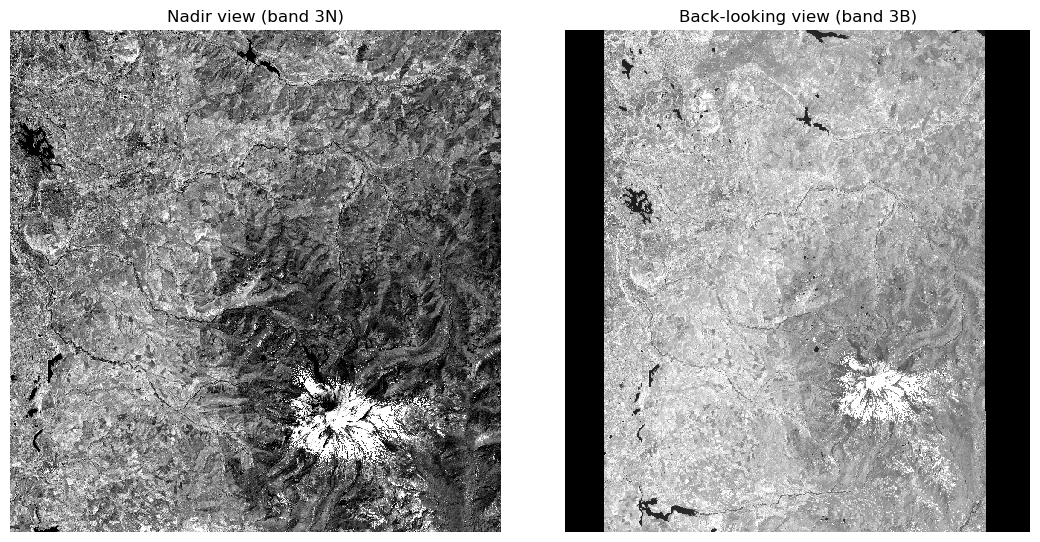

In [4]:
from utils import show_image_pair

show_image_pair(
    f"{DATA}/out-Band3N.tif",
    f"{DATA}/out-Band3B.tif",
    ("Nadir view (band 3N)", "Back-looking view (band 3B)"),
)

Both images as the satellite took them, shown at 1/8 size. They aren't on a map yet: each has its own shape and pixel grid, which is what the next step fixes.

## 4. Orthorectify onto a reference DEM

ASP's `mapproject` drapes each image over an existing coarse map of the terrain (the Copernicus 30 m DEM), so that both images sit on the same map grid. Stereo then only has to find the small differences the coarse map misses, which makes it faster and more reliable on steep terrain. [Why orthorectify first](https://stereopipeline-quickstart.readthedocs.io/en/latest/concepts/orthorectification.html).

> About a minute.

In [5]:
for view in ("3N", "3B"):
    if Path(f"{DATA}/out-Band{view}_ortho.tif").exists():
        print(f"{DATA}/out-Band{view}_ortho.tif exists — skipping mapproject. Delete it to reprocess.")
    else:
        run(f"""
            mapproject --t_srs {T_SRS} --tr 15 --t_projwin {T_PROJWIN} \
                {REF_DEM} \
                {DATA}/out-Band{view}.tif {DATA}/out-Band{view}.xml \
                {DATA}/out-Band{view}_ortho.tif
            """,
            log=f"{LOGS}/mapproject_{view}.log",
            label=f"Orthorectifying band {view}",
        )

mapproject --t_srs EPSG:32610 --tr 15 --t_projwin 577305 5172975 615705 5209035 ../data/aster_rainier/ref/cop30_rainier.tif ../data/aster_rainier/out-Band3N.tif ../data/aster_rainier/out-Band3N.xml ../data/aster_rainier/out-Band3N_ortho.tif


✅ **Orthorectifying band 3N**: done in 12 s. Full log: `../data/aster_rainier/logs/mapproject_3N.log`

mapproject --t_srs EPSG:32610 --tr 15 --t_projwin 577305 5172975 615705 5209035 ../data/aster_rainier/ref/cop30_rainier.tif ../data/aster_rainier/out-Band3B.tif ../data/aster_rainier/out-Band3B.xml ../data/aster_rainier/out-Band3B_ortho.tif


✅ **Orthorectifying band 3B**: done in 11 s. Full log: `../data/aster_rainier/logs/mapproject_3B.log`

## 5. The orthorectified images

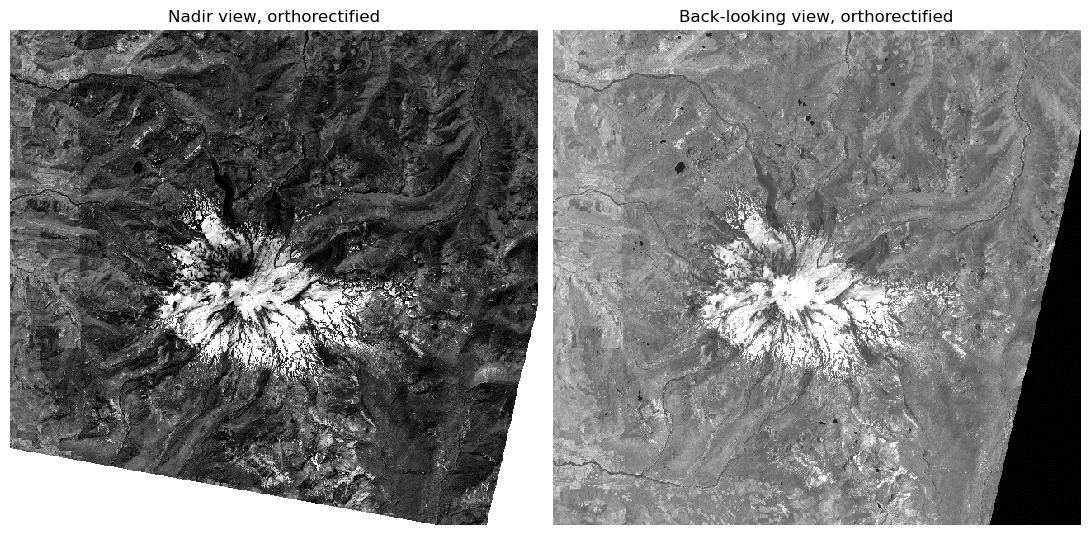

In [6]:
show_image_pair(
    f"{DATA}/out-Band3N_ortho.tif",
    f"{DATA}/out-Band3B_ortho.tif",
    ("Nadir view, orthorectified", "Back-looking view, orthorectified"),
    downsample=4,
)

The same two images, now on one map grid with north up. The blank edges are outside the image.

## 6. Stereo matching and the DEM

ASP's `parallel_stereo` finds, for every pixel, where the same spot appears in the other image, and turns each match into a height. `point2dem` then grids the heights into a DEM with 30 m pixels. [How matching works](https://stereopipeline-quickstart.readthedocs.io/en/latest/concepts/stereo-photogrammetry.html).

While it runs, the cell first shows the features it matched between the two images, then a map of the area, divided into the tiles stereo works through (dashed lines), which fills in as each tile finishes: the offsets between the two images, east-west and north-south, and then the heights that come out of them.

> About 7 minutes.

parallel_stereo -t aster --stereo-algorithm asp_mgm --subpixel-mode 9 --dem ../data/aster_rainier/ref/cop30_rainier.tif --processes 1 --threads-multiprocess 4 --job-size-w 1280 --job-size-h 1202 --matches-per-tile 300 --ip-per-tile 1500 --matches-per-tile-params 512 640 ../data/aster_rainier/out-Band3N_ortho.tif ../data/aster_rainier/out-Band3B_ortho.tif ../data/aster_rainier/out-Band3N.xml ../data/aster_rainier/out-Band3B.xml ../data/aster_rainier/stereo/run


✅ **Height (m)**: done in 3 min 14 s. Full log: `../data/aster_rainier/logs/parallel_stereo.log`

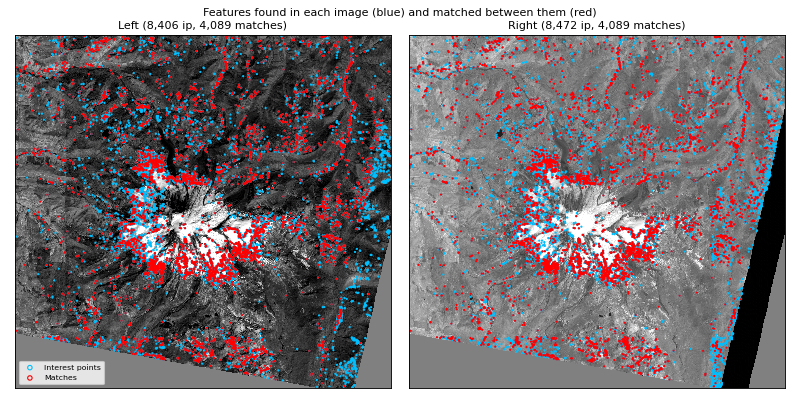

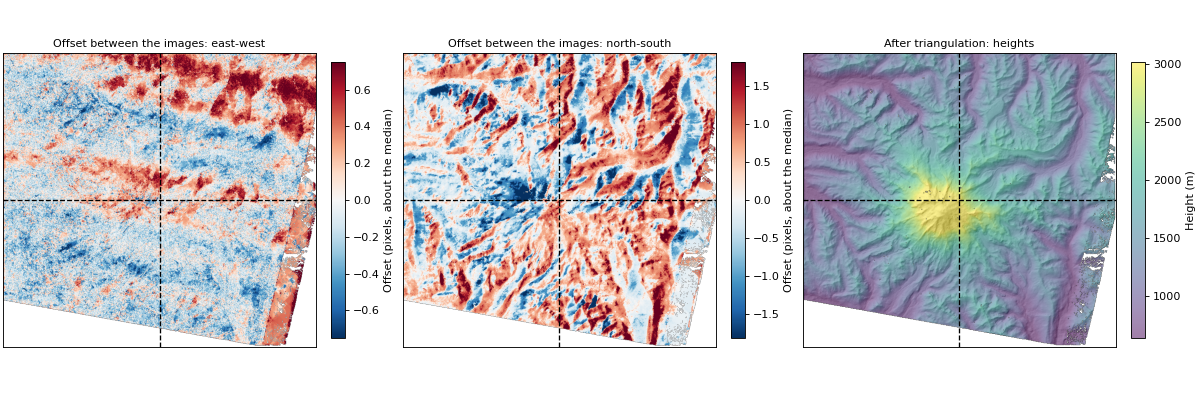

point2dem --tr 30 -r earth --auto-proj-center --errorimage ../data/aster_rainier/stereo/run-PC.tif


✅ **Gridding the points into a DEM**: done in 4 s. Full log: `../data/aster_rainier/logs/point2dem.log`

In [7]:
if Path(f"{DATA}/stereo/run-DEM.tif").exists():
    print(f"{DATA}/stereo/run-DEM.tif exists — skipping stereo. Delete {DATA}/stereo/ to reprocess.")
else:
    run_stereo(f"""
        parallel_stereo -t aster \
            --stereo-algorithm asp_mgm \
            --subpixel-mode 9 \
            --dem {REF_DEM} \
            --processes 1 --threads-multiprocess 4 \
            --job-size-w 1280 --job-size-h 1202 \
            --matches-per-tile 300 --ip-per-tile 1500 --matches-per-tile-params 512 640 \
            {DATA}/out-Band3N_ortho.tif {DATA}/out-Band3B_ortho.tif \
            {DATA}/out-Band3N.xml {DATA}/out-Band3B.xml \
            {DATA}/stereo/run
        """,
        prefix=f"{DATA}/stereo/run",
        log=f"{LOGS}/parallel_stereo.log",
    )
    run(
        f"point2dem --tr 30 -r earth --auto-proj-center --errorimage {DATA}/stereo/run-PC.tif",
        log=f"{LOGS}/point2dem.log",
        label="Gridding the points into a DEM",
    )

Above, the features found in each image (blue) and the ones matched between them (red); stereo uses these to decide where to search. Below, the offset between the two input images at every pixel, split into its east-west and north-south parts. This is [relief displacement](https://stereopipeline-quickstart.readthedocs.io/en/latest/concepts/orthorectification.html): the two views look from different directions, so the same bit of ground sits in a slightly different place in each image, by an amount that depends on its height. Any error left in the cameras adds a shift that is the same everywhere. The offsets are only a pixel or two here, because orthorectification already removed most of the displacement; stereo measures what is left. The wavy north-south bands in the east-west offsets are [satellite jitter](https://stereopipeline-quickstart.readthedocs.io/en/latest/concepts/bundle-adjustment.html#jitter-which-bundle-adjustment-cannot-fix): a small, regular wobble in the sensor's pointing as it flew, which shifts whole rows of pixels together. Right, the heights triangulated from those offsets, as a hillshade with elevation in color.

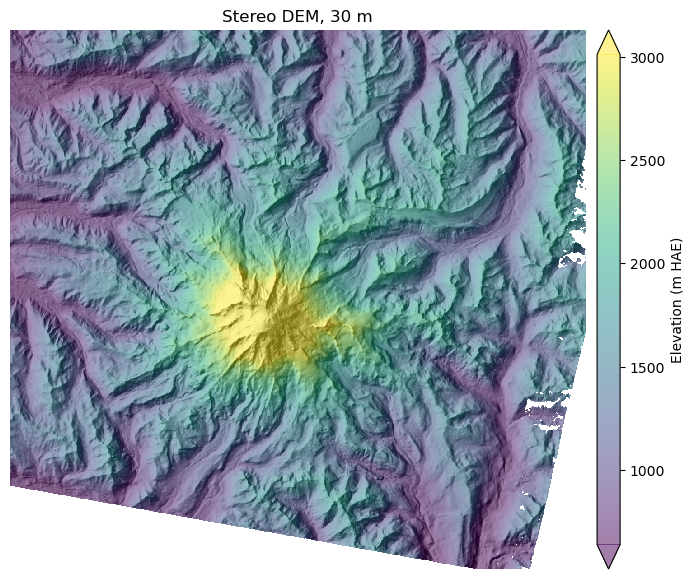

In [8]:
from utils import show_dem_hillshade

show_dem_hillshade(f"{DATA}/stereo/run-DEM.tif", title="Stereo DEM, 30 m", hillshade_fn=f"{DATA}/stereo/run-DEM_hs.tif")

Mount Rainier from above: the summit in the middle, its glaciers and ridges, and the river valleys around it, as a hillshade (the terrain lit from several directions at once, so every slope shows) with elevation in color. White spots are places stereo could not match.

## 7. Report

`asp_report`, from `asp-plot`, writes a PDF with everything about the run: the images, the viewing geometry, the matches, the DEM, and how it compares with the reference map and with [ICESat-2](https://stereopipeline-quickstart.readthedocs.io/en/latest/concepts/alignment.html), a satellite that measures heights directly with a laser. [What's in the report](https://stereopipeline-quickstart.readthedocs.io/en/latest/concepts/visualization.html). Three of its figures appear below.

> About a minute.

asp_report --directory ../data/aster_rainier --stereo-directory stereo --reference-dem ../data/aster_rainier/ref/cop30_rainier.tif --subset-km 5 --atl06sr-time-range 2018-10-14,2020-10-14 --reuse-selections ../data/aster_rainier/icesat2_shipped/figure_selections.yml --figures-directory ../data/aster_rainier/stereo/report_figures --report-filename rainier_aster_report.pdf


✅ **Making the report**: done in 30 s. Full log: `../data/aster_rainier/logs/asp_report.log`

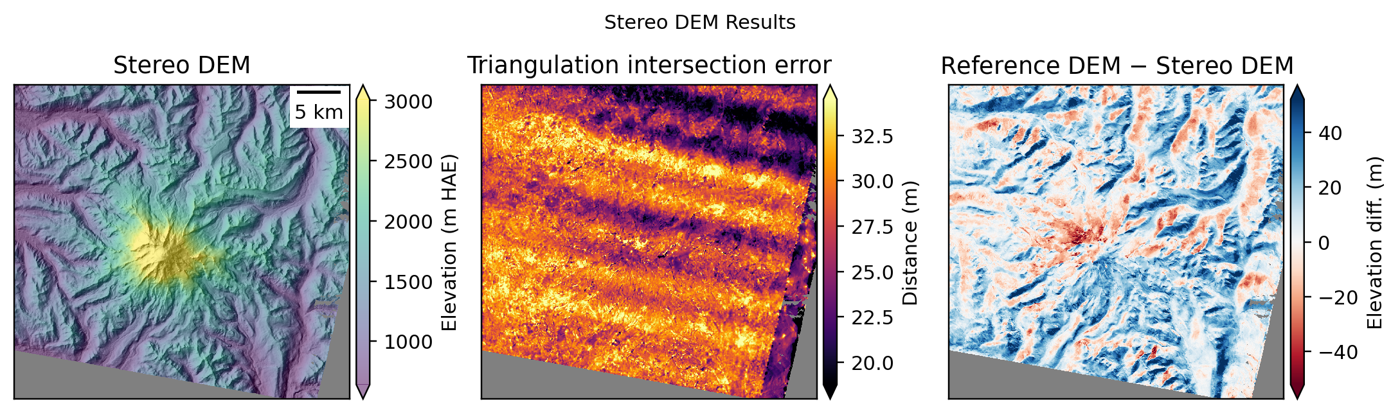

**Report figure 5.** The DEM, its triangulation intersection error, and its difference from the reference DEM.

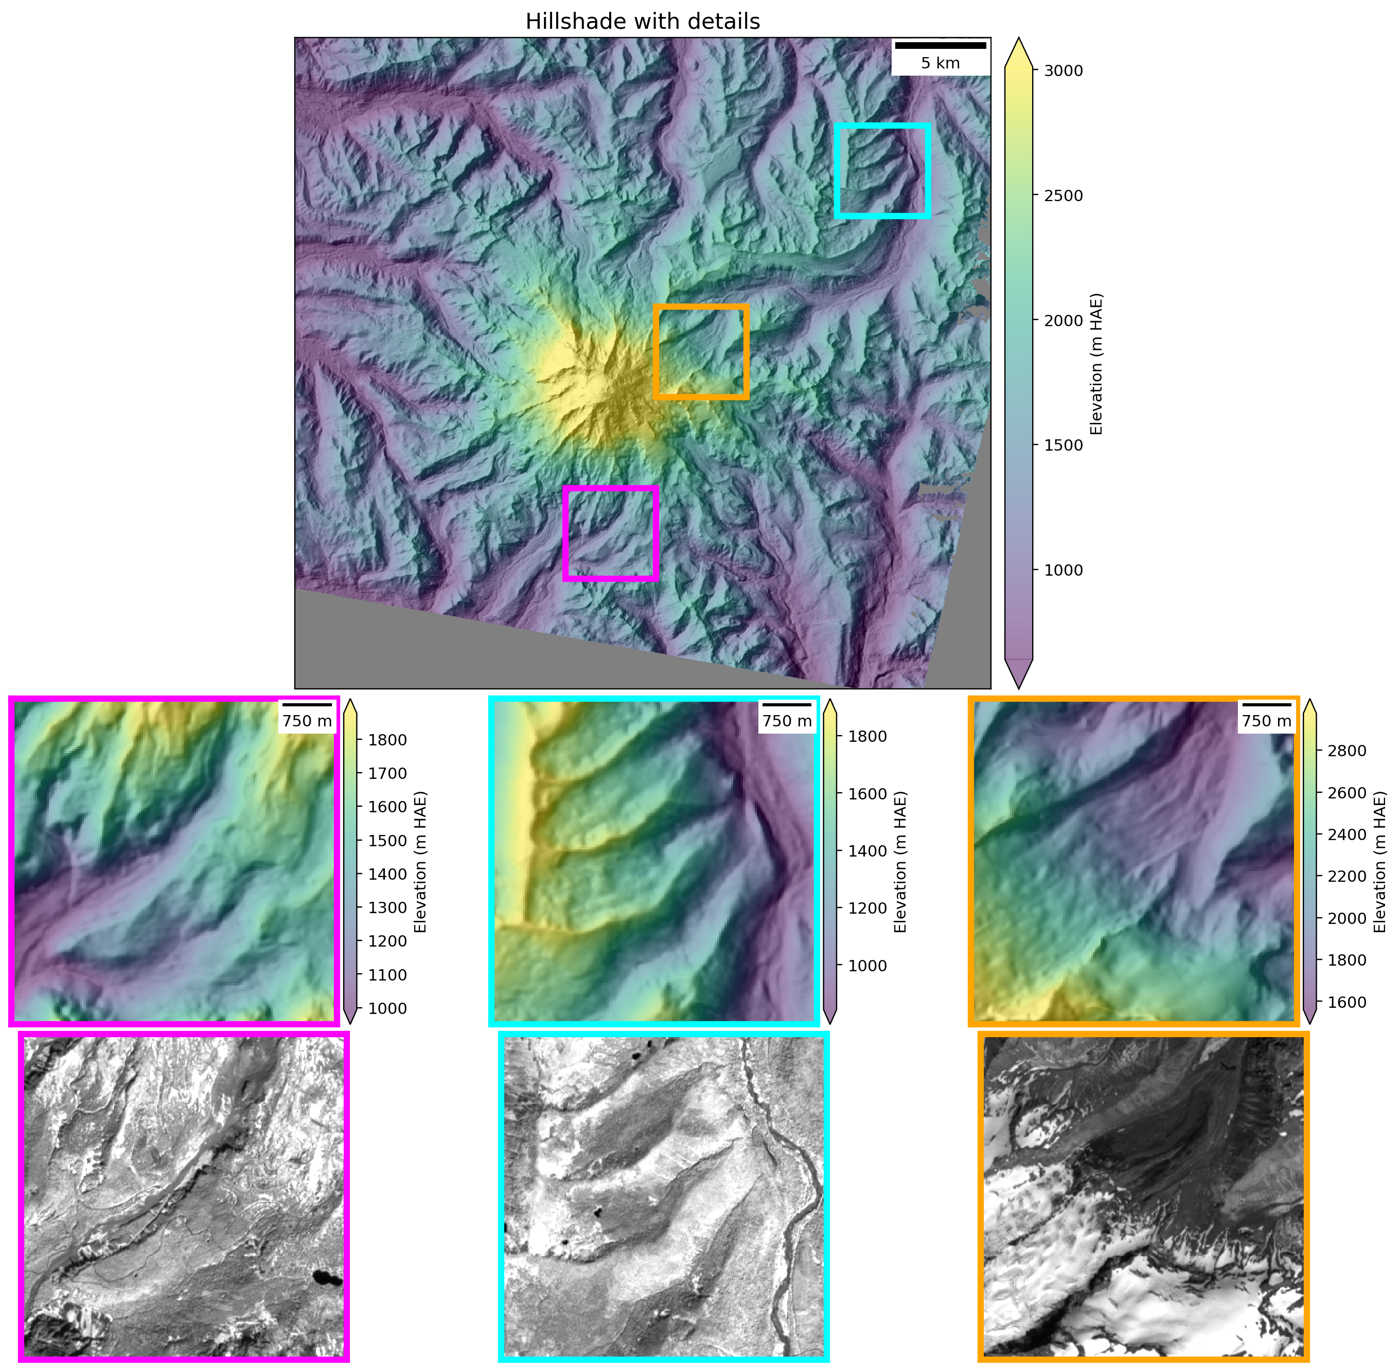

**Report figure 6.** A hillshade of the DEM, with zoomed details.

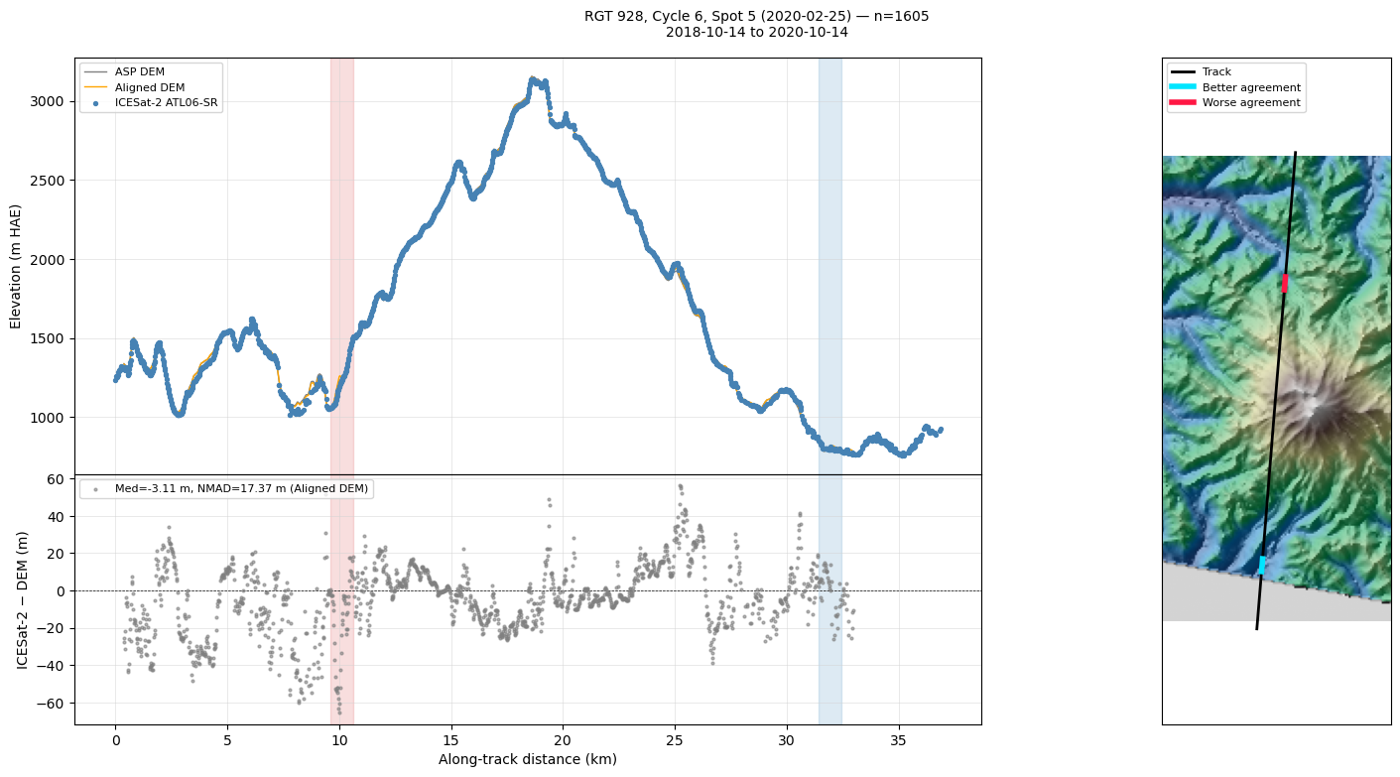

**Report figure 13.** The DEM along one ICESat-2 track, before and after the shift onto the ICESat-2 points, and the difference after it.

In [9]:
from utils import show_report_figures

FIGS = f"{DATA}/stereo/report_figures"
if Path(f"{DATA}/stereo/rainier_aster_report.pdf").exists():
    print(f"{DATA}/stereo/rainier_aster_report.pdf exists — skipping asp_report. Delete it to regenerate.")
else:
    reuse = "" if FRESH_ICESAT2 else f"--reuse-selections {SHIPPED_SELECTIONS}"
    run(f"""
        asp_report \
            --directory {DATA} \
            --stereo-directory stereo \
            --reference-dem {REF_DEM} \
            --subset-km 5 \
            --atl06sr-time-range 2018-10-14,2020-10-14 \
            {reuse} \
            --figures-directory {FIGS} \
            --report-filename rainier_aster_report.pdf
        """,
        log=f"{LOGS}/asp_report.log",
        label="Making the report",
    )

show_report_figures(FIGS)

### 📄 [Open the report (PDF)](../data/aster_rainier/stereo/rainier_aster_report.pdf)

## 8. Download the results

The cell below puts the results into one zip file, `aster_rainier_results.zip`, in the top folder of the file explorer on the left. It includes:

- the `asp-plot` report, 
- the DEM,
- its hillshade,
- the map of triangulation error, 
- and the two orthorectified images (as 8-bit copies, to keep the zip small).

Each file is named by place, sensor and date, and the GeoTIFFs are Cloud Optimized GeoTIFFs with overviews, so they open quickly in QGIS, ArcGIS or any other GIS. A QGIS project file in the zip opens all of them at once. When the zip is ready, a notification at the bottom right points to it; right-click it in the explorer and choose **Download**.

> A few seconds.

In [10]:
from utils import zip_results

# Each result's file, its name in the zip (what it is, where, when, from what), and its kind.
NAME = "rainier_aster_20170731"
zip_results(
    "../aster_rainier_results.zip",
    [
        (f"{DATA}/stereo/rainier_aster_report.pdf", f"{NAME}_report.pdf", "pdf"),
        (f"{DATA}/stereo/run-DEM.tif", f"{NAME}_dem_30m.tif", "dem"),
        (f"{DATA}/stereo/run-DEM_hs.tif", f"{NAME}_dem_30m_hillshade.tif", "hillshade"),
        (f"{DATA}/stereo/run-IntersectionErr.tif", f"{NAME}_dem_30m_intersection_error.tif", "error"),
        (f"{DATA}/out-Band3N_ortho.tif", f"{NAME}_band3N_nadir_ortho_15m.tif", "image"),
        (f"{DATA}/out-Band3B_ortho.tif", f"{NAME}_band3B_backward_ortho_15m.tif", "image"),
    ],
    title=NAME,
)

✅ **Zipping the results**: done in 1 s

### Results: `aster_rainier_results.zip` (28 MB, 7 files)

- `rainier_aster_20170731_report.pdf`
- `rainier_aster_20170731_dem_30m.tif`
- `rainier_aster_20170731_dem_30m_hillshade.tif`
- `rainier_aster_20170731_dem_30m_intersection_error.tif`
- `rainier_aster_20170731_band3N_nadir_ortho_15m.tif`
- `rainier_aster_20170731_band3B_backward_ortho_15m.tif`
- `rainier_aster_20170731.qgs`

To save it to your computer, right-click it in the file explorer on the left and choose **Download**. Unzip it and open `rainier_aster_20170731.qgs` in QGIS to see everything at once.

### How to download it

The zip is in the **file explorer**, the panel on the left of the window with `data/`, `notebooks/` and the zip (if the panel is hidden, click the top icon in the bar at the far left). Right-click the zip there and choose **Download**; your browser then saves it like any download.

![The end of Tutorial 1: (1) the report link, (2) the results line, (3) the zip in the file explorer](../start/figures/launch-done.png)

The first time you right-click in the explorer, your browser may ask whether this page can see your clipboard. Click **Allow** or **Block**, whichever you prefer; the menu with **Download** works either way.

![The browser's clipboard question, with Block and Allow buttons](../start/figures/clipboard-prompt.png)

## What's next

→ [Tutorial 2: WorldView-3, Los Peñasquitos Canyon](02_worldview_ucsd.ipynb) moves to sharp commercial imagery: a 1 m DEM from a WorldView-3 pair, compared with and aligned to ICESat-2 laser heights. [Tutorial 3](03_worldview_ucsd_blend.ipynb) blends three pairs of the same place into one DEM.

→ [What ASP is and where it came from](https://stereopipeline-quickstart.readthedocs.io/en/latest/start/what-is-asp.html), and [the pipeline as a whole](https://stereopipeline-quickstart.readthedocs.io/en/latest/concepts/pipeline-overview.html).